# Voltammetry & Diagnostics: LSV, Multi-Scan-Rate CV & Declarative Plotting

This tutorial demonstrates turnkey simulation and diagnostic analysis of **Linear Sweep Voltammetry (LSV)** and **Cyclic Voltammetry (CV)** using [`softpotato.techniques`](../api/techniques.md).

### Learning Objectives
1. Simulate reversible LSV with `LinearSweepVoltammetry` and `simulate()`.
2. Use the declarative plotting interfaces (`result.plot()`, `result.plot_summary()`, and `plot_sweep()`).
3. Run a multi-scan-rate quasi-reversible CV sweep with `simulate_sweep()`.
4. Extract peak metrics (`find_peaks`, `plot_peaks`), diffusivity (`analyze_randles_sevcik`, `plot_randles_sevcik`), and standard rate constant $k^0$ (`analyze_nicholson`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from softpotato.constants import FARADAY
from softpotato.geometry import PlanarGeometry
from softpotato.grid import GeometricExpandingMesh
from softpotato.reactions import (
    ButlerVolmer,
    CustomMechanism,
    NernstianEquilibrium,
    Species,
)
from softpotato.solver import DirichletBC, NeumannBC
from softpotato.techniques import (
    CyclicVoltammetry,
    LinearSweepVoltammetry,
    analyze_nicholson,
    analyze_randles_sevcik,
    find_peaks,
    plot_peaks,
    plot_randles_sevcik,
    plot_sweep,
    simulate,
    simulate_sweep,
)

# Shared physical parameters (SI units)
D = 1e-9  # m^2/s
c_bulk = 1.0  # mol/m^3 (1 mM)
area = 1e-4  # m^2 (1 cm^2)

ox = Species(
    "Ox",
    diffusivity=D,
    bulk_concentration=c_bulk,
    standard_potential=0.0,
    n_electrons=1,
)
red = Species(
    "Red", diffusivity=D, bulk_concentration=0.0, standard_potential=0.0, n_electrons=-1
)
geom = PlanarGeometry(area=area)

## 1. Linear Sweep Voltammetry & Summary Plotting

We simulate a reversible LSV experiment and inspect the result with `result.plot()` (which defaults to `'voltammogram'`) and `result.plot_summary()` (which renders the 2x2 overview of voltammogram, $I(t)$, $E(t)$, and $c(x, t)$).

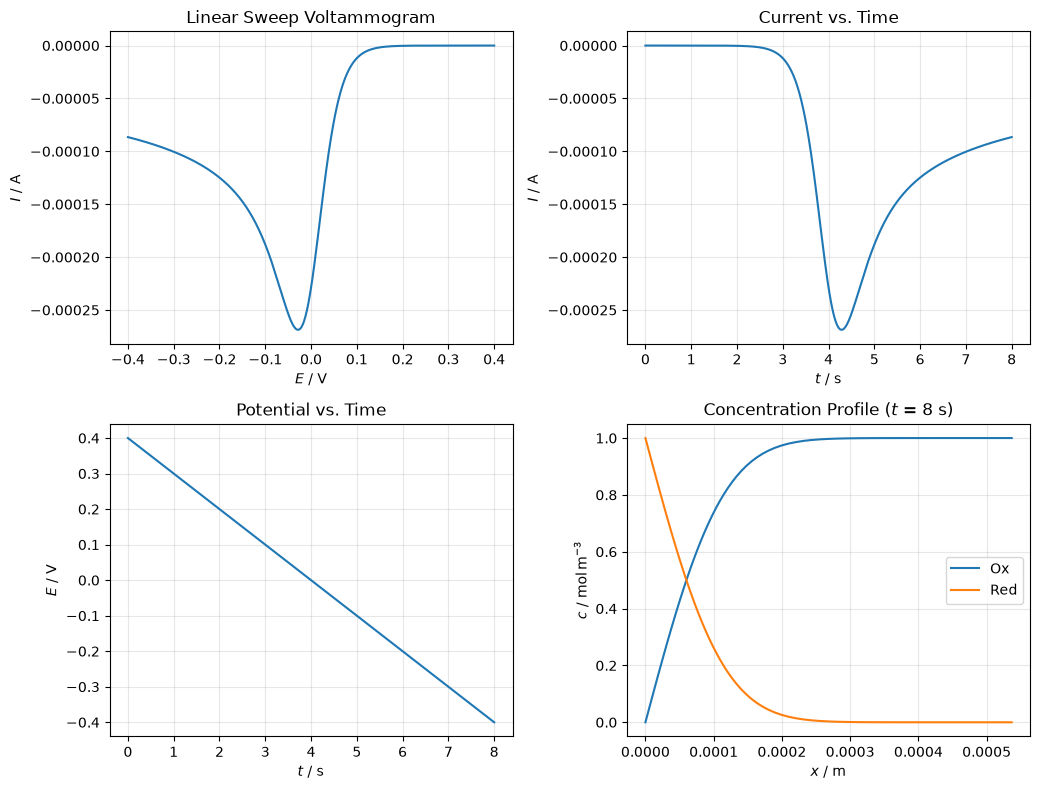

In [2]:
lsv = LinearSweepVoltammetry(E_start=0.4, E_end=-0.4, scan_rate=0.1)
res_lsv = simulate(
    lsv,
    [ox, red],
    geometry=geom,
    kinetics=NernstianEquilibrium(E0=0.0, n=1),
)

fig_summary, axes = res_lsv.plot_summary()
plt.show()

## 2. Multi-Scan-Rate CV Sweep with Butler–Volmer Kinetics

Using `simulate_sweep()`, we sweep the scan rate $v \in \{0.05, 0.1, 0.2, 0.5\}\,\text{V/s}$ for a quasi-reversible couple ($k^0 = 10^{-4}\,\text{m/s}$, $\alpha = 0.5$) and overlay all voltammograms with `plot_sweep()`.

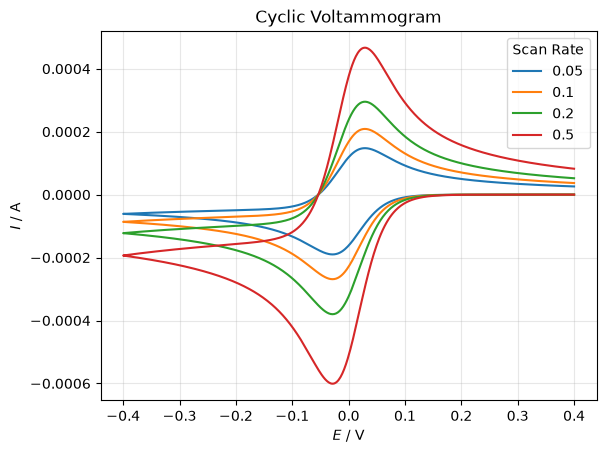

In [3]:
scan_rates = [0.05, 0.1, 0.2, 0.5]

cv_sweep = simulate_sweep(
    lambda v: CyclicVoltammetry(
        E_start=0.4, E_vertex1=-0.4, E_vertex2=0.4, scan_rate=v
    ),
    [ox, red],
    values=scan_rates,
    geometry=geom,
    kinetics=NernstianEquilibrium(E0=0.0, n=1),
)

fig, ax = plot_sweep(cv_sweep, legend_title="Scan Rate")
plt.show()

## 3. Peak Detection, Randles–Ševčík Regression & Nicholson $k^0$ Extraction

We inspect the $v = 0.1\,\text{V/s}$ voltammogram with `find_peaks()` and `plot_peaks()`, perform Randles–Ševčík regression across the sweep via `analyze_randles_sevcik()`, and estimate $k^0$ from peak-to-peak separation $\Delta E_p$ via `analyze_nicholson()`.

E_pa = 0.0290 V, E_pc = -0.0285 V
Delta E_p = 57.42 mV, |I_pa/I_pc| = 0.777


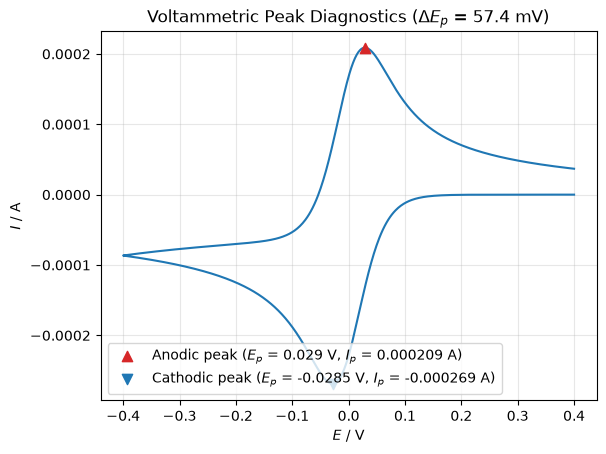

Estimated D (Randles-Sevcik) = 1.000e-09 m^2/s (true: 1.000e-09 m^2/s)


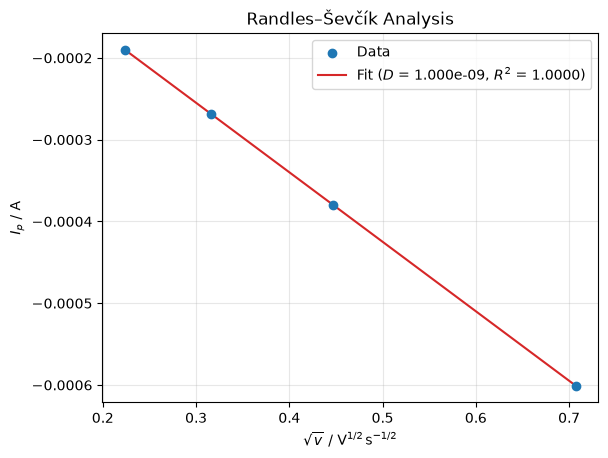

Nicholson Psi = 0.913, estimated k0 = 1.010e-04 m/s (true: 1.000e-04 m/s)


In [4]:
res_01 = cv_sweep[0.1]
peaks = find_peaks(res_01)
print(
    f"E_pa = {peaks.anodic_peak.E_peak:.4f} V, E_pc = {peaks.cathodic_peak.E_peak:.4f} V"
)
print(
    f"Delta E_p = {peaks.delta_Ep * 1e3:.2f} mV, |I_pa/I_pc| = {peaks.peak_current_ratio:.3f}"
)

fig_pk, ax_pk = plot_peaks(res_01, peaks)
plt.show()

rs_fit = analyze_randles_sevcik(cv_sweep, n=1, area=area, c_bulk=c_bulk)
print(f"Estimated D (Randles-Sevcik) = {rs_fit.d:.3e} m^2/s (true: {D:.3e} m^2/s)")
fig_rs, ax_rs = plot_randles_sevcik(cv_sweep, rs_fit)
plt.show()

# Quasi-reversible Butler-Volmer CV for Nicholson k0 extraction
k0_true = 1e-4
cv_bv = CyclicVoltammetry(
    E_start=0.45, E_vertex1=-0.45, E_vertex2=0.45, scan_rate=0.1, dE=0.005
)
mesh_bv = GeometricExpandingMesh(
    0.0, 6.0 * np.sqrt(D * cv_bv.duration), n_points=65, gamma=1.10
)
inv_half_cell = 2.0 / float(mesh_bv.nodes[1] - mesh_bv.nodes[0])
bv = ButlerVolmer(k0=k0_true, alpha=0.5, E0=0.0, n=1)


def bv_rates(c, x, t):
    kf, kb = bv.rate_constants(float(cv_bv.potential(t)))
    j_bv = float(kf) * c["Ox"][0] - float(kb) * c["Red"][0]
    r_ox = np.zeros_like(c["Ox"])
    r_red = np.zeros_like(c["Red"])
    r_ox[0] = -inv_half_cell * j_bv
    r_red[0] = inv_half_cell * j_bv
    return {"Ox": r_ox, "Red": r_red}


mech_bv = CustomMechanism(species=[ox, red], rates=bv_rates, name="QuasiRevBV")
res_bv = simulate(
    cv_bv,
    mech_bv,
    geometry=geom,
    grid=mesh_bv,
    bc_overrides={
        "Ox": (NeumannBC(0.0), DirichletBC(c_bulk)),
        "Red": (NeumannBC(0.0), DirichletBC(0.0)),
    },
    solver_kwargs={"method": "Radau", "rtol": 1e-6, "atol": 1e-9},
)
kf_arr, kb_arr = bv.rate_constants(res_bv.potential)
i_bv = (
    -FARADAY
    * area
    * (
        np.asarray(kf_arr) * res_bv["Ox"][:, 0]
        - np.asarray(kb_arr) * res_bv["Red"][:, 0]
    )
)
nich = analyze_nicholson(res_bv.potential, i_bv, D=D, scan_rate=0.1)
print(
    f"Nicholson Psi = {nich.psi:.3f}, estimated k0 = {nich.k0:.3e} m/s (true: {k0_true:.3e} m/s)"
)